In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

K = 3        # number of recommendations per query
RUNS = 100   # number of experiments per agent

In [43]:
# (title, description, topic)
CATALOG = [
    ("Intro to Machine Learning", "machine learning models train data prediction algorithms", "ml"),
    ("Deep Learning with Neural Networks", "neural networks deep learning training layers gradient", "ml"),
    ("Supervised Learning in Practice", "classification regression labeled data model evaluation", "ml"),
    ("Natural Language Processing Basics", "text language model tokens embeddings machine learning", "ml"),
    ("Modern Web Development", "html css javascript websites frontend browser design", "web"),
    ("Backend APIs with Python", "server api database requests python backend web", "web"),
    ("React for Beginners", "react components javascript frontend interface web apps", "web"),
    ("Full Stack Web Projects", "frontend backend database deployment web application", "web"),
    ("Data Analysis with Pandas", "data analysis tables pandas cleaning statistics python", "data"),
    ("Data Visualization", "charts plots visualization data storytelling matplotlib", "data"),
    ("Statistics for Data Science", "probability statistics distributions hypothesis data", "data"),
    ("SQL and Databases", "sql queries tables database data joins", "data"),
    ("Network Security Fundamentals", "network security firewall attacks protection traffic", "sec"),
    ("Ethical Hacking Basics", "hacking penetration testing vulnerabilities security tools", "sec"),
    ("Cryptography Essentials", "encryption keys cryptography security protocols secrets", "sec"),
    ("Secure Software Development", "secure coding vulnerabilities software security testing", "sec"),
    ("Android App Development", "android mobile apps kotlin interface devices", "mob"),
    ("iOS Apps with Swift", "ios swift mobile apps iphone interface", "mob"),
    ("Cross-Platform Mobile Apps", "mobile apps flutter cross platform devices interface", "mob"),
    ("Mobile App Design", "mobile design interface usability apps screens", "mob"),
]

texts = [title + " " + desc for title, desc, _ in CATALOG]
labels = np.array([topic for _, _, topic in CATALOG])

vec = TfidfVectorizer()
X = vec.fit_transform(texts)   # TF-IDF matrix of the catalog
print(X.shape)

(20, 113)


In [44]:
TOPIC_WORDS = {
    "ml":   ["learning", "model", "neural", "training", "data", "prediction", "text", "algorithms"],
    "web":  ["web", "javascript", "frontend", "backend", "html", "server", "browser", "database"],
    "data": ["data", "analysis", "statistics", "tables", "charts", "pandas", "sql", "probability"],
    "sec":  ["security", "hacking", "encryption", "vulnerabilities", "network", "attacks", "testing", "protection"],
    "mob":  ["mobile", "apps", "android", "ios", "interface", "swift", "devices", "design"],
}
TOPICS = list(TOPIC_WORDS)

def make_query(seed):
    rng = np.random.default_rng(seed)
    topic = str(rng.choice(TOPICS))
    words = list(rng.choice(TOPIC_WORDS[topic], size=3, replace=False))
    other = rng.choice([t for t in TOPICS if t != topic])
    words.append(rng.choice(TOPIC_WORDS[other]))   # one noise word
    return topic, " ".join(words)

for s in range(3):
    print(make_query(s))

('mob', 'devices android ios learning')
('data', 'pandas probability tables design')
('mob', 'apps android mobile web')


In [45]:
def add_noise(query, noise, rng):
    out = []
    for w in query.split():
        r = rng.random()
        if r < noise / 2:
            continue                                  # word lost (incomplete info)
        if r < noise and len(w) > 3:                  # typo: swap two adjacent letters
            i = rng.integers(0, len(w) - 1)
            w = w[:i] + w[i+1] + w[i] + w[i+2:]
        out.append(w)
    return " ".join(out)

def recommend(agent, query, rng):
    if agent == "random":
        return rng.permutation(len(CATALOG))[:K]
    if agent == "keyword":
        q = set(query.split())
        scores = np.array([len(q & set(t.split())) for t in texts], dtype=float)
    else:                                                # "tfidf" agent
        q = vec.transform([query])
        scores = cosine_similarity(q, X).ravel()
    scores = scores + rng.random(len(scores)) * 1e-6     # random tie-break
    return np.argsort(-scores)[:K]

def simulate(agent, seed, noise=0.0):
    topic, query = make_query(seed)
    rng = np.random.default_rng(seed + 1000)
    query = add_noise(query, noise, np.random.default_rng(seed + 2000))
    top = recommend(agent, query, rng)
    return float((labels[top] == topic).mean())          # Precision@K

In [46]:
for agent in ["random", "keyword", "tfidf"]:
    print(agent, simulate(agent, seed=1))

random 0.3333333333333333
keyword 0.6666666666666666
tfidf 0.6666666666666666


In [47]:
rows = []
for agent in ["random", "keyword", "tfidf"]:
    for seed in range(RUNS):
        rows.append({"agent": agent, "precision": simulate(agent, seed)})

df = pd.DataFrame(rows)
summary = df.groupby("agent")["precision"].agg(["mean", "std"]).round(3)
print(summary)

          mean    std
agent                
keyword  0.763  0.219
random   0.217  0.214
tfidf    0.733  0.183


In [48]:
NOISE_LEVELS = [0.0, 0.2, 0.4, 0.6, 0.8]

rows = []
for agent in ["random", "keyword", "tfidf"]:
    for noise in NOISE_LEVELS:
        for seed in range(RUNS):
            rows.append({"agent": agent, "noise": noise,
                         "precision": simulate(agent, seed, noise)})

df_noise = pd.DataFrame(rows)
noise_summary = df_noise.groupby(["noise", "agent"])["precision"].mean().unstack().round(3)
print(noise_summary)

agent  keyword  random  tfidf
noise                        
0.0      0.763   0.217  0.733
0.2      0.720   0.217  0.687
0.4      0.667   0.217  0.637
0.6      0.577   0.217  0.560
0.8      0.443   0.217  0.433


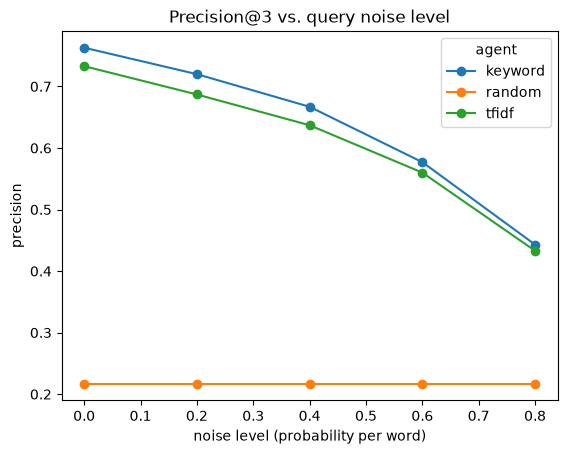

In [49]:
noise_summary.plot(marker="o")
plt.title("Precision@3 vs. query noise level")
plt.xlabel("noise level (probability per word)")
plt.ylabel("precision")
plt.show()

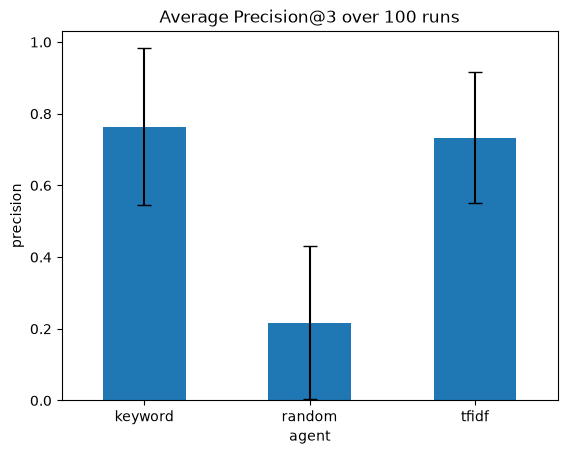

In [50]:
summary["mean"].plot(kind="bar", yerr=summary["std"], capsize=5)
plt.title("Average Precision@3 over 100 runs")
plt.ylabel("precision")
plt.xticks(rotation=0)
plt.show()